# 21.1 Define the Business Problem

**Concept**

Turn a vague need into a precise ML task: input, output, success metric and cost of mistakes. Problem chosen for this challenge: **automatically read handwritten digits** (forms, cheques, postal codes).

**Why it is required / what problem it solves**

Without a clear problem statement you can optimise the wrong thing. The metric, dataset and model choice in every later step come from this one.

In [1]:
# Business problem written as a small, checkable spec
spec = {
    "Problem": "Read handwritten digits on forms / cheques / postal codes automatically",
    "ML task": "10-class image classification (digit 0-9)",
    "Success metric": "Accuracy on unseen images >= 97%",
    "Costly mistake": "A wrong digit that is NOT caught (needs human review)",
}
for k, v in spec.items():
    print(f"{k:15}: {v}")

# Simple cost model (ASSUMED numbers, only to show why accuracy matters)
digits_per_day = 100_000
cost_fix_error = 20      # cost units to find and fix one wrong digit
for name, acc in [("Weak model", 0.90), ("Target model", 0.97)]:
    errors = digits_per_day * (1 - acc)
    print(f"{name}: {errors:,.0f} errors/day -> {errors * cost_fix_error:,.0f} cost units/day")

Problem        : Read handwritten digits on forms / cheques / postal codes automatically
ML task        : 10-class image classification (digit 0-9)
Success metric : Accuracy on unseen images >= 97%
Costly mistake : A wrong digit that is NOT caught (needs human review)
Weak model: 10,000 errors/day -> 200,000 cost units/day
Target model: 3,000 errors/day -> 60,000 cost units/day


**What this example tells us (according to the topic)**

- Input = digit image, output = digit 0-9, metric = accuracy >= 97% on unseen images.
- With an **assumed** 100,000 digits/day, a 90% model makes 10,000 errors/day (200,000 cost units) while a 97% model makes 3,000 (60,000). Cost numbers are assumptions, only to show why the target matters.

**AI/ML Example**

"Classify chest X-rays as normal/abnormal with recall >= 95%" is defined before any data is touched.

**Business Example**

A bank reading cheque amounts: every undetected wrong digit becomes a customer complaint or a financial loss.

**AI/ML Engineer Use Case**

Write the problem spec, metric and cost of errors with stakeholders first. It becomes the acceptance test for releasing the model.

# 21.2 Select a Dataset

**Concept**

Pick data that matches the problem, is legal to use, and is the right size for your compute.

**Why it is required / what problem it solves**

A model can only learn what the data shows. A mismatched dataset gives a model that looks fine in the notebook and fails in real use.

In [2]:
from sklearn.datasets import load_digits

digits = load_digits()          # ships with scikit-learn -> no download needed
print("Dataset      : handwritten digits (UCI optical recognition, in scikit-learn)")
print("Images       :", digits.images.shape[0])
print("Image size   :", digits.images.shape[1:], "(grayscale)")
print("Classes      :", len(digits.target_names), "->", [int(c) for c in digits.target_names])
print("Why chosen   : small, clean, runs on CPU in seconds, same pipeline as MNIST/CIFAR")

Dataset      : handwritten digits (UCI optical recognition, in scikit-learn)
Images       : 1797
Image size   : (8, 8) (grayscale)
Classes      : 10 -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Why chosen   : small, clean, runs on CPU in seconds, same pipeline as MNIST/CIFAR


**What this example tells us (according to the topic)**

- scikit-learn digits: 1,797 grayscale images of size 8x8, 10 classes (0-9).
- It ships inside scikit-learn, so it works offline and trains on a CPU in seconds.
- Trade-off: it is tiny and clean. The pipeline is the same one used for MNIST/CIFAR, but results here will not transfer to messy real scans (see topic 15).

**AI/ML Example**

Choosing CIFAR-10 for a quick object-recognition prototype, ImageNet for pretraining a large model.

**Business Example**

A retailer collects photos of its own shelves instead of using generic web pictures, because production images will look like shelf photos.

**AI/ML Engineer Use Case**

Before selecting data check: licence, label quality, size, and how close the images are to production images.

# 21.3 Inspect the Dataset

**Concept**

Look at shapes, data types, value ranges, missing values, duplicates and actual sample images before modelling.

**Why it is required / what problem it solves**

Broken data (wrong range, blanks, duplicates, wrong labels) silently ruins models. Finding it now is far cheaper than debugging a model later.

Shape            : (1797, 8, 8)
Data type        : float64
Pixel range      : 0.0 to 16.0
Missing values   : 0
Duplicate images : 0
Mean pixel value : 4.88


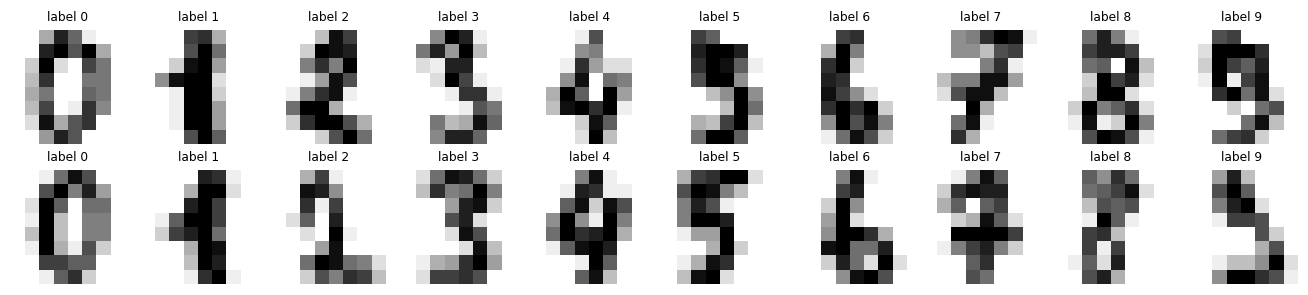

In [3]:
import numpy as np
import matplotlib.pyplot as plt

imgs, labels = digits.images, digits.target
print("Shape            :", imgs.shape)
print("Data type        :", imgs.dtype)
print("Pixel range      :", imgs.min(), "to", imgs.max())
print("Missing values   :", int(np.isnan(imgs).sum()))
print("Duplicate images :", len(imgs) - len(np.unique(imgs.reshape(len(imgs), -1), axis=0)))
print("Mean pixel value :", round(float(imgs.mean()), 2))

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(imgs[i], cmap="gray_r"); ax.set_title(f"label {labels[i]}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

**What this example tells us (according to the topic)**

- Shape (1797, 8, 8), float64, pixel values 0 to 16 (so we must scale by 16 later).
- 0 missing values, 0 duplicate images.
- The sample grid shows clear, centred digits with matching labels.

**AI/ML Example**

Noticing that part of a medical image set is rotated or carries a hospital watermark the model could cheat on.

**Business Example**

Checking a product-photo set for blank or duplicate pictures before paying for labelling and training.

**AI/ML Engineer Use Case**

Add automatic data checks (shape, range, duplicates) to the pipeline and fail the run if they break.

# 21.4 Identify the Target

**Concept**

The target is what the model must predict. Here it is the digit shown in the image, so this is **multi-class classification** with 10 classes.

**Why it is required / what problem it solves**

The target type decides the output layer, the loss function and the metric. A wrong choice here makes everything after it wrong.

In [4]:
X_raw, y = digits.images, digits.target      # X_raw = input images, y = target
print("Target variable  : y (the digit written in the image)")
print("Target type      : categorical, 10 classes -> multi-class classification")
print("Unique values    :", np.unique(y))
print("Images vs labels :", len(X_raw), "images,", len(y), "labels (one label per image)")

# How the label looks to a neural network (one-hot vector)
print("Label of image 0 :", y[0], "-> one-hot:", np.eye(10, dtype=int)[y[0]])

Target variable  : y (the digit written in the image)
Target type      : categorical, 10 classes -> multi-class classification
Unique values    : [0 1 2 3 4 5 6 7 8 9]
Images vs labels : 1797 images, 1797 labels (one label per image)
Label of image 0 : 0 -> one-hot: [1 0 0 0 0 0 0 0 0 0]


**What this example tells us (according to the topic)**

- `y` holds one value from 0-9 per image (1,797 images = 1,797 labels).
- A network sees the label as a one-hot vector: digit 0 becomes `[1 0 0 0 0 0 0 0 0 0]`.
- So the output layer needs 10 neurons + softmax and the loss is cross-entropy.

**AI/ML Example**

Defect / no defect is binary; defect type is multi-class; defect location needs object detection.

**Business Example**

An insurer: "is the car damaged?" (binary) versus "how severe is the damage?" (multi-class).

**AI/ML Engineer Use Case**

Pick output layer, loss and metric from the target type, and confirm images and labels line up one-to-one.

# 21.5 Analyze Classes

**Concept**

Count how many images each class has and check whether the classes are balanced.

**Why it is required / what problem it solves**

On imbalanced data accuracy is misleading: a model can ignore a rare class and still score high.

class 0: 178 images (9.9%)
class 1: 182 images (10.1%)
class 2: 177 images (9.8%)
class 3: 183 images (10.2%)
class 4: 181 images (10.1%)
class 5: 182 images (10.1%)
class 6: 181 images (10.1%)
class 7: 179 images (10.0%)
class 8: 174 images (9.7%)
class 9: 180 images (10.0%)
Imbalance ratio (max/min): 1.05


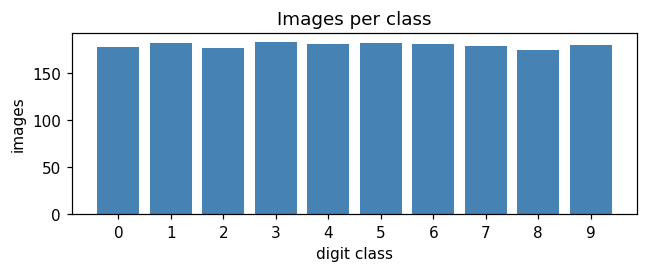

In [5]:
counts = np.bincount(y)
for c, n in enumerate(counts):
    print(f"class {c}: {n} images ({n / len(y):.1%})")
print("Imbalance ratio (max/min):", round(counts.max() / counts.min(), 2))

plt.figure(figsize=(6, 2.6))
plt.bar(range(10), counts, color="steelblue"); plt.xticks(range(10))
plt.xlabel("digit class"); plt.ylabel("images"); plt.title("Images per class")
plt.tight_layout(); plt.show()

**What this example tells us (according to the topic)**

- Classes have 174 to 183 images, imbalance ratio 1.05.
- The data is balanced, so plain accuracy is a fair metric and no class weights or resampling are needed.

**AI/ML Example**

Rare-event images (defects, fraud, disease) where 99% are normal need recall/F1 and class weights.

**Business Example**

A factory where 1 in 1,000 parts is defective: an "always OK" model scores 99.9% accuracy and catches nothing.

**AI/ML Engineer Use Case**

Plot class counts first. If the ratio is large, use stratified splits, class weights and per-class metrics.

# 21.6 Prepare the Images

**Concept**

Convert raw images into model-ready arrays: scale pixels, add a channel axis, and split into train / validation / test.

**Why it is required / what problem it solves**

Networks train badly on unscaled input. A separate untouched test set is the only honest measure of real performance. Stratified splits keep the class mix equal.

In [6]:
from sklearn.model_selection import train_test_split

X = (X_raw / 16.0)[:, None, :, :]          # scale 0-16 -> 0-1, add channel axis (N, 1, 8, 8)

# 60% train / 20% validation / 20% test, stratified = same class mix in every split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(X_tr, y_tr, test_size=0.25, stratify=y_tr, random_state=42)

print("Train :", X_tr.shape, "| Val :", X_va.shape, "| Test :", X_te.shape)
print("Pixel range after scaling:", X.min(), "to", X.max())
for name, labels_ in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(name, "class share (0..9):", np.round(np.bincount(labels_) / len(labels_), 2))

Train : (1077, 1, 8, 8) | Val : (360, 1, 8, 8) | Test : (360, 1, 8, 8)
Pixel range after scaling: 0.0 to 1.0
train class share (0..9): [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
val class share (0..9): [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
test class share (0..9): [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


**What this example tells us (according to the topic)**

- Pixels scaled 0-16 to 0-1, shape (N, 1, 8, 8).
- Split 1,077 train / 360 validation / 360 test, each about 10% per class.
- Validation is used for choices (tuning, augmentation). Test is kept for the final comparison only.

**AI/ML Example**

ImageNet models expect 224x224 images with mean/std normalisation.

**Business Example**

A mobile app receives photos of every size; they must be resized exactly as during training.

**AI/ML Engineer Use Case**

Put preprocessing in one function used by both training and serving to avoid train/serve skew.

# 21.7 Build a Baseline

**Concept**

The simplest reasonable models you must beat: always predict the most common class, and logistic regression on raw pixels.

**Why it is required / what problem it solves**

A baseline gives the number that justifies extra complexity. "90% accuracy" means nothing without something to compare to.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

flat = lambda a: a.reshape(len(a), -1)       # image -> 64 numbers

dummy = DummyClassifier(strategy="most_frequent").fit(flat(X_tr), y_tr)
logreg = LogisticRegression(max_iter=5000).fit(flat(X_tr), y_tr)

print("Dummy (always most common class) val accuracy:", round(dummy.score(flat(X_va), y_va), 3))
print("Logistic Regression on raw pixels val accuracy:", round(logreg.score(flat(X_va), y_va), 3))

Dummy (always most common class) val accuracy: 0.103
Logistic Regression on raw pixels val accuracy: 0.972


**What this example tells us (according to the topic)**

- Dummy model: 0.103 validation accuracy (about chance for 10 classes).
- Logistic regression on 64 raw pixels: 0.972.
- So the bar is already high: a CNN must beat 97.2% to be worth using.

**AI/ML Example**

Compare a deep model against logistic regression or a random forest on the same split.

**Business Example**

If a simple model already meets the 97% target, shipping it is cheaper and easier to maintain.

**AI/ML Engineer Use Case**

Log the baseline in the experiment tracker. Every new model must beat it on the same data split.

# 21.8 Build a CNN

**Concept**

A CNN slides small filters over the image (convolution), applies ReLU, shrinks with pooling, then classifies with a dense layer. Here it is written in **pure NumPy** (PyTorch/TensorFlow are not installed in this environment) with backpropagation and the Adam optimizer.

**Why it is required / what problem it solves**

The same small filter is reused at every position, so it can detect a stroke or curve anywhere in the image, and pooling adds some tolerance to small movements.

In [8]:
from numpy.lib.stride_tricks import sliding_window_view

class NumpyCNN:
    """Conv(3x3) -> ReLU -> MaxPool(2x2) -> Dense -> Softmax, trained with Adam (pure NumPy)."""
    def __init__(self, n_filters=8, n_classes=10, lr=0.01, l2=1e-4, seed=0):
        r = np.random.RandomState(seed)
        self.F, self.lr, self.l2, self.rng, self.t, self.frozen = n_filters, lr, l2, r, 0, set()
        self.p = {"Wc": r.randn(9, n_filters) * np.sqrt(2 / 9), "bc": np.zeros(n_filters),
                  "Wd": r.randn(16 * n_filters, n_classes) * np.sqrt(2 / (16 * n_filters)),
                  "bd": np.zeros(n_classes)}
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}
        self.v = {k: np.zeros_like(v) for k, v in self.p.items()}

    def n_params(self): return sum(v.size for v in self.p.values())

    def forward(self, X):
        N = len(X)
        pad = np.pad(X[:, 0], ((0, 0), (1, 1), (1, 1)))
        patches = sliding_window_view(pad, (3, 3), axis=(1, 2)).reshape(N * 64, 9)   # every 3x3 window
        a = np.maximum(patches @ self.p["Wc"] + self.p["bc"], 0)                    # conv + ReLU
        a6 = a.reshape(N, 4, 2, 4, 2, self.F)
        pooled = a6.max(axis=(2, 4))                                                # 2x2 max-pool
        flat_ = pooled.reshape(N, -1)
        self.cache = (N, patches, a6, pooled, flat_)
        return flat_ @ self.p["Wd"] + self.p["bd"]

    def predict_proba(self, X):
        out = []
        for i in range(0, len(X), 512):
            z = self.forward(X[i:i + 512]); e = np.exp(z - z.max(1, keepdims=True))
            out.append(e / e.sum(1, keepdims=True))
        return np.vstack(out)

    def predict(self, X): return self.predict_proba(X).argmax(1)

    def step(self, xb, yb):
        z = self.forward(xb); N, patches, a6, pooled, flat_ = self.cache
        e = np.exp(z - z.max(1, keepdims=True)); P = e / e.sum(1, keepdims=True)
        loss = -np.log(P[np.arange(N), yb] + 1e-12).mean()
        d = P.copy(); d[np.arange(N), yb] -= 1; d /= N
        g = {"Wd": flat_.T @ d + self.l2 * self.p["Wd"], "bd": d.sum(0)}
        dpool = (d @ self.p["Wd"].T).reshape(pooled.shape)
        mask = (a6 == pooled[:, :, None, :, None, :]); mask = mask / mask.sum(axis=(2, 4), keepdims=True)
        da = (mask * dpool[:, :, None, :, None, :]).reshape(N * 64, self.F)
        dz = da * (a6.reshape(N * 64, self.F) > 0)
        g["Wc"] = patches.T @ dz + self.l2 * self.p["Wc"]; g["bc"] = dz.sum(0)
        self.t += 1
        for k in self.p:                                   # Adam update (skip frozen layers)
            if k in self.frozen: continue
            self.m[k] = 0.9 * self.m[k] + 0.1 * g[k]; self.v[k] = 0.999 * self.v[k] + 0.001 * g[k] ** 2
            self.p[k] -= self.lr * (self.m[k] / (1 - 0.9 ** self.t)) / (np.sqrt(self.v[k] / (1 - 0.999 ** self.t)) + 1e-8)
        return loss

    def fit(self, X, y, Xv=None, yv=None, epochs=30, bs=64, augment=None):
        self.hist, self.best = {"loss": [], "val_acc": []}, (-1, None)
        for ep in range(epochs):
            idx, tot = self.rng.permutation(len(X)), 0
            for i in range(0, len(X), bs):
                b = idx[i:i + bs]; xb = X[b] if augment is None else augment(X[b], self.rng)
                tot += self.step(xb, y[b]) * len(b)
            self.hist["loss"].append(tot / len(X))
            if Xv is not None:
                acc = (self.predict(Xv) == yv).mean(); self.hist["val_acc"].append(acc)
                if acc > self.best[0]: self.best = (acc, {k: v.copy() for k, v in self.p.items()})
        return self

cnn = NumpyCNN(n_filters=8, lr=0.01).fit(X_tr, y_tr, X_va, y_va, epochs=30)
print("Trainable parameters:", cnn.n_params())
for ep in [0, 4, 9, 19, 29]:
    print(f"epoch {ep + 1:2d} | train loss {cnn.hist['loss'][ep]:.3f} | val acc {cnn.hist['val_acc'][ep]:.3f}")
print("Train accuracy:", round((cnn.predict(X_tr) == y_tr).mean(), 3),
      "| Val accuracy:", round((cnn.predict(X_va) == y_va).mean(), 3))
print("Baseline LogReg val accuracy:", round(logreg.score(flat(X_va), y_va), 3))

Trainable parameters: 1370
epoch  1 | train loss 1.864 | val acc 0.756
epoch  5 | train loss 0.198 | val acc 0.947
epoch 10 | train loss 0.091 | val acc 0.969
epoch 20 | train loss 0.032 | val acc 0.986
epoch 30 | train loss 0.014 | val acc 0.981
Train accuracy: 0.999 | Val accuracy: 0.981
Baseline LogReg val accuracy: 0.972


**What this example tells us (according to the topic)**

- 1,370 trainable parameters. Training loss falls from 1.864 to 0.014 in 30 epochs.
- Validation accuracy 0.981 vs baseline 0.972.
- Train accuracy 0.999 vs validation 0.981: a small gap, so mild overfitting.

**AI/ML Example**

The conv -> pool -> dense pattern is the building block of larger networks such as ResNet.

**Business Example**

Reading digits from scanned forms without hand-designed features.

**AI/ML Engineer Use Case**

Start with a small CNN and check the loss really falls. Then scale up, and reimplement in PyTorch for production.

# 21.9 Apply Transfer Learning

**Concept**

Reuse features learned on one task (source) to help another task (target) that has little labelled data. **Frozen** = keep the filters fixed and train a new head. **Fine-tune** = update everything.

**Why it is required / what problem it solves**

Labelled images are expensive. Pretrained features can cut the data and training time needed.

In [9]:
# Transfer learning, offline version: pretrain on a SOURCE task (digits 0-4),
# reuse the learned conv filters on a TARGET task (digits 5-9) that has little labelled data.
# (No internet here, so ImageNet-pretrained models cannot be downloaded.)
src_tr = np.isin(y_tr, [0, 1, 2, 3, 4])
source = NumpyCNN(n_filters=8, lr=0.01).fit(X_tr[src_tr], y_tr[src_tr], epochs=30)

tgt_pool = np.where(np.isin(y_tr, [5, 6, 7, 8, 9]))[0]
tgt_va = np.isin(y_va, [5, 6, 7, 8, 9])

def with_source_filters(seed, lr):
    m = NumpyCNN(8, lr=lr, seed=seed)
    m.p["Wc"], m.p["bc"] = source.p["Wc"].copy(), source.p["bc"].copy()
    return m

print("Target task = classes 5-9 | val accuracy, mean of 5 random label subsets")
print(f"{'labelled imgs':>13} | {'scratch':>8} | {'frozen conv':>11} | {'fine-tune all':>13}")
for n_labels in [15, 30, 50]:
    r = {"scratch": [], "frozen": [], "tuned": []}
    for seed in range(5):
        pick = np.random.RandomState(seed).choice(tgt_pool, n_labels, replace=False)
        Xs, ys = X_tr[pick], y_tr[pick]
        scratch = NumpyCNN(8, lr=0.01, seed=seed).fit(Xs, ys, epochs=60)
        frozen = with_source_filters(seed, 0.01); frozen.frozen = {"Wc", "bc"}; frozen.fit(Xs, ys, epochs=60)
        tuned = with_source_filters(seed, 0.003).fit(Xs, ys, epochs=60)
        for k, m in [("scratch", scratch), ("frozen", frozen), ("tuned", tuned)]:
            r[k].append((m.predict(X_va[tgt_va]) == y_va[tgt_va]).mean())
    print(f"{n_labels:>13} | {np.mean(r['scratch']):8.3f} | {np.mean(r['frozen']):11.3f} | {np.mean(r['tuned']):13.3f}")

Target task = classes 5-9 | val accuracy, mean of 5 random label subsets
labelled imgs |  scratch | frozen conv | fine-tune all
           15 |    0.761 |       0.749 |         0.691
           30 |    0.873 |       0.848 |         0.798
           50 |    0.912 |       0.903 |         0.848


**What this example tells us (according to the topic)**

- Source task: digits 0-4. Target task: digits 5-9 with only 15, 30 or 50 labelled images.
- **Result: transfer did not help here.** Scratch 0.761 / 0.873 / 0.912, frozen 0.749 / 0.848 / 0.903, fine-tune 0.691 / 0.798 / 0.848.
- Likely reason (not tested): the conv layer is only 8 small filters, easy to learn from a few dozen images, so there is little to reuse. ImageNet-scale pretrained backbones could not be downloaded offline.
- Lesson: always compare transfer against training from scratch.

**AI/ML Example**

Fine-tuning an ImageNet-pretrained ResNet on a few hundred medical images.

**Business Example**

A startup with 200 labelled product photos fine-tunes a pretrained model instead of training from zero.

**AI/ML Engineer Use Case**

Try a frozen backbone first, then fine-tune with a small learning rate, and keep a scratch run to prove transfer actually helps.

# 21.10 Experiment with Augmentation

**Concept**

Create modified copies of training images (shift, rotate, add noise) on the fly while training.

**Why it is required / what problem it solves**

More variety can reduce overfitting and improve robustness, but only if the changes look like real variation.

augmentation        150 images  1077 images   (val accuracy, mean of 3 runs)
none                     0.922        0.981
shift 1px (p=.5)         0.907        0.978
rotate 5deg              0.891        0.965
noise 0.05               0.919        0.984

Best on full training set: noise 0.05


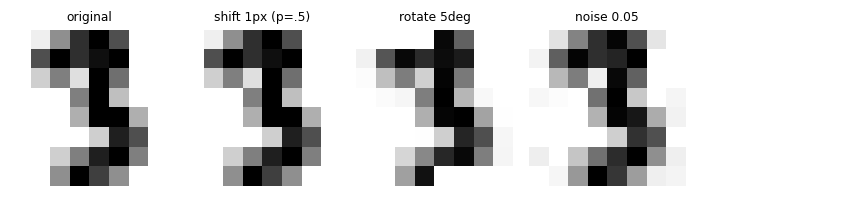

In [10]:
from scipy.ndimage import rotate

def make_aug(max_shift=0, max_rot=0, noise=0.0, p=1.0):
    """Build an augmentation: random shift (px), rotation (deg), pixel noise; applied with probability p."""
    def aug(xb, rng):
        out = xb.copy()
        for i in range(len(xb)):
            if rng.rand() > p: continue
            img = xb[i, 0]
            if max_rot: img = rotate(img, rng.uniform(-max_rot, max_rot), reshape=False, order=1, mode="constant")
            if max_shift:
                dx, dy = rng.randint(-max_shift, max_shift + 1, size=2)
                img = np.roll(np.roll(img, dx, 0), dy, 1)
                if dx > 0: img[:dx, :] = 0
                if dx < 0: img[dx:, :] = 0
                if dy > 0: img[:, :dy] = 0
                if dy < 0: img[:, dy:] = 0
            if noise: img = np.clip(img + rng.normal(0, noise, img.shape), 0, 1)
            out[i, 0] = img
        return out
    return aug

variants = {"none": None, "shift 1px (p=.5)": make_aug(max_shift=1, p=0.5),
            "rotate 5deg": make_aug(max_rot=5), "noise 0.05": make_aug(noise=0.05)}

fig, axes = plt.subplots(1, 5, figsize=(8, 1.9))
axes[0].imshow(X_tr[0, 0], cmap="gray_r"); axes[0].set_title("original", fontsize=8)
for ax, (name, fn) in zip(axes[1:], list(variants.items())[1:]):
    ax.imshow(fn(X_tr[:1], np.random.RandomState(3))[0, 0], cmap="gray_r"); ax.set_title(name, fontsize=8)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

print(f"{'augmentation':18}{'150 images':>12}{'1077 images':>13}   (val accuracy, mean of 3 runs)")
scores = {}
for name, fn in variants.items():
    row = []
    for n in [150, len(X_tr)]:
        accs = []
        for seed in range(3):
            pick = np.random.RandomState(seed).choice(len(X_tr), n, replace=False)
            m = NumpyCNN(8, lr=0.01, seed=seed).fit(X_tr[pick], y_tr[pick], epochs=40, augment=fn)
            accs.append((m.predict(X_va) == y_va).mean())
        row.append(np.mean(accs))
    scores[name] = row[1]
    print(f"{name:18}{row[0]:12.3f}{row[1]:13.3f}")
best_aug_name = max(scores, key=scores.get); best_aug = variants[best_aug_name]
print("\nBest on full training set:", best_aug_name)

**What this example tells us (according to the topic)**

- Val accuracy with 150 / 1,077 training images: none 0.922 / 0.981, shift 0.907 / 0.978, rotate 0.891 / 0.965, noise 0.919 / 0.984.
- On these tiny, already centred 8x8 images shift and rotation **hurt** (a 1 px move is 12% of the image). Noise is neutral to slightly better; 0.984 vs 0.981 is within run-to-run noise, so noise was picked only because it scored highest.
- Clean validation accuracy is not the whole story: shift robustness is checked in topic 15.

**AI/ML Example**

Flips, crops and colour jitter for photos. Flips would be wrong for digits because they change the meaning.

**Business Example**

A retail app sees photos in different lighting, so brightness augmentation matches real use.

**AI/ML Engineer Use Case**

Treat augmentation as a hyperparameter: test one change at a time and view samples to confirm the label is still valid.

# 21.11 Tune Important Parameters

**Concept**

Hyperparameters are set before training. Grid search tries combinations and picks the best by **validation** accuracy.

**Why it is required / what problem it solves**

Defaults are rarely best. Tuning on validation (never on test) finds a better setting without fooling yourself.

In [11]:
import pandas as pd

rows = []
for lr in [0.001, 0.003, 0.01, 0.03]:
    for nf in [4, 8, 16]:
        accs = [(NumpyCNN(nf, lr=lr, seed=s).fit(X_tr, y_tr, epochs=25).predict(X_va) == y_va).mean() for s in range(2)]
        rows.append({"learning_rate": lr, "n_filters": nf, "val_acc": round(float(np.mean(accs)), 4)})

grid = pd.DataFrame(rows)
print(grid.pivot(index="learning_rate", columns="n_filters", values="val_acc"))
best_cfg = grid.sort_values("val_acc", ascending=False).iloc[0]
best_lr, best_nf = float(best_cfg["learning_rate"]), int(best_cfg["n_filters"])
print("\nBest on validation -> learning_rate:", best_lr, "| n_filters:", best_nf, "| val_acc:", best_cfg["val_acc"])

n_filters          4       8       16
learning_rate                        
0.001          0.8931  0.9375  0.9514
0.003          0.9569  0.9639  0.9681
0.010          0.9653  0.9708  0.9778
0.030          0.9736  0.9847  0.9792

Best on validation -> learning_rate: 0.03 | n_filters: 8 | val_acc: 0.9847


**What this example tells us (according to the topic)**

- Grid: 4 learning rates x 3 filter counts, 2 seeds each, 25 epochs.
- lr 0.001 is too slow for 25 epochs (0.893 to 0.951). Best: lr 0.03 with 8 filters = 0.985.
- 16 filters at lr 0.03 gave 0.979, so more filters were not better.
- Top results differ by about 1%, roughly 3-4 images of 360.

**AI/ML Example**

Learning rate is usually the highest-impact hyperparameter in deep learning.

**Business Example**

Tuning costs compute time; stop when gains become smaller than the noise.

**AI/ML Engineer Use Case**

Use random search or a tool like Optuna for larger spaces, log every run, and never touch the test set while tuning.

# 21.12 Analyze Errors

**Concept**

Study which images the model gets wrong and which classes it confuses, using a confusion matrix and per-class accuracy.

**Why it is required / what problem it solves**

Overall accuracy hides where the model fails. Error analysis tells you what to fix next.

Validation errors: 7 of 360
Per-class accuracy: {0: 1.0, 1: 1.0, 2: 0.97, 3: 0.97, 4: 1.0, 5: 1.0, 6: 0.94, 7: 1.0, 8: 1.0, 9: 0.92}
Most common mistakes (true -> predicted): [('9->8', 2), ('9->1', 1), ('6->8', 1), ('6->4', 1), ('3->9', 1)]


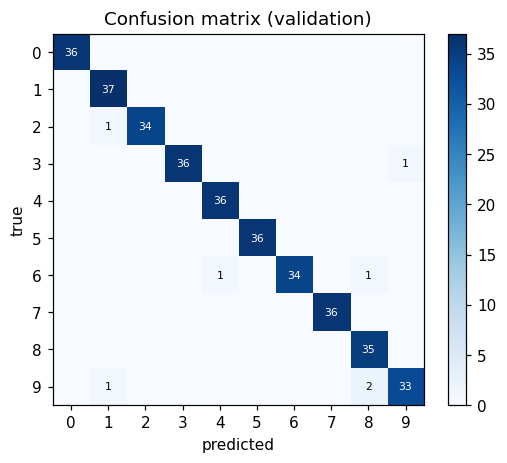

In [12]:
from sklearn.metrics import confusion_matrix

pred_va = cnn.predict(X_va)
cm = confusion_matrix(y_va, pred_va)
print("Validation errors:", int((pred_va != y_va).sum()), "of", len(y_va))
print("Per-class accuracy:", {c: round(float(cm[c, c] / cm[c].sum()), 2) for c in range(10)})

off = [(cm[i, j], i, j) for i in range(10) for j in range(10) if i != j and cm[i, j] > 0]
print("Most common mistakes (true -> predicted):", [(f"{i}->{j}", int(n)) for n, i, j in sorted(off, reverse=True)[:5]])

plt.figure(figsize=(5, 4.2)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xlabel("predicted"); plt.ylabel("true"); plt.xticks(range(10)); plt.yticks(range(10))
for i in range(10):
    for j in range(10):
        if cm[i, j]: plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                              color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.title("Confusion matrix (validation)"); plt.tight_layout(); plt.show()

**What this example tells us (according to the topic)**

- 7 errors out of 360 validation images.
- Weakest classes: 9 (0.92) and 6 (0.94). Most common mistake: 9 -> 8 (2 times); the others happened once.
- With so few errors these patterns are only hints. Closed loops of 8 and 9 look alike at 8x8.

**AI/ML Example**

In medical imaging, confusing two similar diseases points to collecting more examples of those two.

**Business Example**

In cheque reading, 9 vs 8 mix-ups can get an extra manual-check rule.

**AI/ML Engineer Use Case**

Review wrong images by hand, look for label noise and confused class pairs, then target data collection.

# 21.13 Visualize Predictions

**Concept**

Show images with true label, predicted label and confidence, and look at what the filters learned.

**Why it is required / what problem it solves**

Numbers hide problems; pictures build trust. Confidence also shows when the model should not be trusted.

Wrong predictions in this validation set: 7
image 28: true 9, predicted 8, confidence 99%
image 40: true 6, predicted 8, confidence 52%
image 54: true 3, predicted 9, confidence 49%
image 145: true 9, predicted 1, confidence 80%
image 311: true 6, predicted 4, confidence 64%
image 334: true 9, predicted 8, confidence 91%


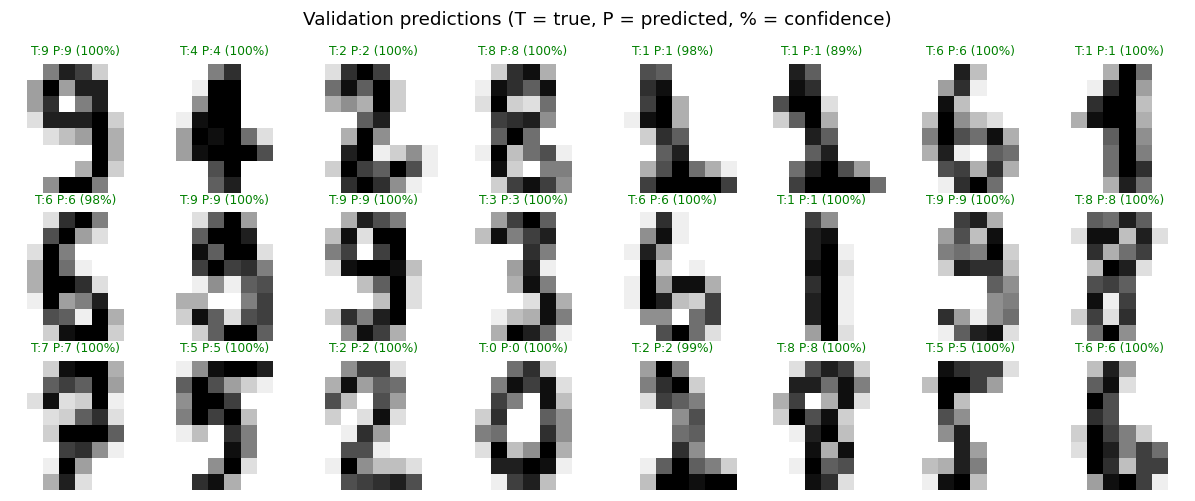

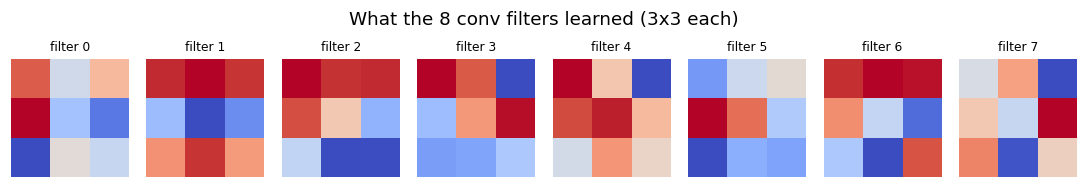

In [13]:
proba = cnn.predict_proba(X_va)
fig, axes = plt.subplots(3, 8, figsize=(11, 4.6))
for ax, i in zip(axes.ravel(), range(24)):
    ok = pred_va[i] == y_va[i]
    ax.imshow(X_va[i, 0], cmap="gray_r"); ax.axis("off")
    ax.set_title(f"T:{y_va[i]} P:{pred_va[i]} ({proba[i].max():.0%})", fontsize=8, color="green" if ok else "red")
plt.suptitle("Validation predictions (T = true, P = predicted, % = confidence)"); plt.tight_layout(); plt.show()

wrong = np.where(pred_va != y_va)[0]
print("Wrong predictions in this validation set:", len(wrong))
for i in wrong[:6]:
    print(f"image {i}: true {y_va[i]}, predicted {pred_va[i]}, confidence {proba[i].max():.0%}")

fig, axes = plt.subplots(1, 8, figsize=(10, 1.7))
for k, ax in enumerate(axes):
    ax.imshow(cnn.p["Wc"][:, k].reshape(3, 3), cmap="coolwarm"); ax.set_title(f"filter {k}", fontsize=8); ax.axis("off")
plt.suptitle("What the 8 conv filters learned (3x3 each)"); plt.tight_layout(); plt.show()

**What this example tells us (according to the topic)**

- Most of the 24 shown images are correct (green); mistakes are red.
- Among the first 6 listed errors, confidence ranges from 49% to 99%: two were confident mistakes (99% and 91%), the rest low confidence (49-80%).
- So a confidence threshold would catch some mistakes but not all.

**AI/ML Example**

Grad-CAM heatmaps show which image regions drove a prediction.

**Business Example**

A review screen shows the model's guess with its confidence so staff only check uncertain cases.

**AI/ML Engineer Use Case**

Build a small dashboard of wrong and low-confidence predictions and feed them into the next training round.

# 21.14 Optimize the Model

**Concept**

Combine the best findings: tuned learning rate and filters, best augmentation, longer training, and keeping the best-validation weights (early stopping).

**Why it is required / what problem it solves**

Single findings only matter once they are combined into one improved model and measured fairly on the untouched test set.

In [14]:
import time

# Final recipe = best params from tuning + best augmentation + more epochs + keep best-validation weights
final = NumpyCNN(best_nf, lr=best_lr, l2=1e-4, seed=0).fit(X_tr, y_tr, X_va, y_va, epochs=60, augment=best_aug)
final.p = final.best[1]                                   # restore best-validation epoch (early-stopping style)

t0 = time.time(); final.predict(X_te); ms = (time.time() - t0) / len(X_te) * 1000
rows = [("Logistic Regression (pixels)", logreg.score(flat(X_va), y_va), logreg.score(flat(X_te), y_te), "-"),
        ("CNN v1 (8 filters, lr 0.01)", (cnn.predict(X_va) == y_va).mean(), (cnn.predict(X_te) == y_te).mean(), cnn.n_params()),
        ("CNN optimized", (final.predict(X_va) == y_va).mean(), (final.predict(X_te) == y_te).mean(), final.n_params())]
print(f"{'Model':32}{'Val acc':>9}{'Test acc':>10}{'Params':>9}")
for name, v, t, p in rows:
    print(f"{name:32}{v:9.3f}{t:10.3f}{str(p):>9}")
print(f"\nInference speed: {ms:.3f} ms per image (CPU, NumPy)")

Model                             Val acc  Test acc   Params
Logistic Regression (pixels)        0.972     0.956        -
CNN v1 (8 filters, lr 0.01)         0.981     0.975     1370
CNN optimized                       0.989     0.978     1370

Inference speed: 0.013 ms per image (CPU, NumPy)


**What this example tells us (according to the topic)**

- Test accuracy: Logistic Regression 0.956, CNN v1 0.975, optimized CNN 0.978 (same 1,370 parameters, about 0.01-0.02 ms per image on CPU; timing varies by machine).
- CNN over logistic regression is +1.9 points (about 7 images of 360). Optimized over v1 is +0.3 points, about 1 image, which is within noise (see topic 15).
- Honest summary: the CNN is a modest gain over a strong baseline on this easy dataset.

**AI/ML Example**

Pruning, quantization and early stopping are common ways to make models smaller or better.

**Business Example**

At roughly 0.01-0.02 ms per image, 100,000 digits per day needs only seconds of CPU time, so accuracy, not cost, is the real concern.

**AI/ML Engineer Use Case**

Freeze the test set, compare all candidates on the same splits, and record the final recipe and random seeds.

# 21.15 Document Limitations

**Concept**

Write down where the model is expected to fail and how sure we are about the results.

**Why it is required / what problem it solves**

It stops over-trust. Stakeholders need known risks before deployment.

In [15]:
from math import sqrt

def wilson(acc, n, z=1.96):                        # 95% confidence interval for an accuracy
    c = (acc + z * z / (2 * n)) / (1 + z * z / n)
    h = z * sqrt(acc * (1 - acc) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h

acc_te = (final.predict(X_te) == y_te).mean()
lo, hi = wilson(acc_te, len(y_te))
print(f"Test accuracy {acc_te:.3f} on {len(y_te)} images -> 95% CI: {lo:.3f} to {hi:.3f}")

# Robustness check: changes the model was not trained for
def shift(a, dx): return np.roll(a, dx, axis=3) * (np.arange(8) >= dx)[None, None, None, :]
noisy = np.clip(X_te + np.random.RandomState(0).normal(0, 0.15, X_te.shape), 0, 1)
shift_trained = NumpyCNN(best_nf, lr=best_lr, seed=0).fit(X_tr, y_tr, epochs=40, augment=make_aug(max_shift=1))

print(f"\n{'test condition':28}{'optimized':>10}{'trained w/ shift aug':>22}")
for name, data in [("clean test images", X_te), ("shifted right by 2 px", shift(X_te, 2)), ("Gaussian noise (0.15)", noisy)]:
    print(f"{name:28}{(final.predict(data) == y_te).mean():10.3f}{(shift_trained.predict(data) == y_te).mean():22.3f}")

Test accuracy 0.978 on 360 images -> 95% CI: 0.957 to 0.989

test condition               optimized  trained w/ shift aug
clean test images                0.978                 0.961
shifted right by 2 px            0.192                 0.692
Gaussian noise (0.15)            0.958                 0.836


**What this example tells us (according to the topic)**

- Test accuracy 0.978 on only 360 images, 95% CI 0.957 to 0.989.
- Robustness: shifting images right by 2 px drops the optimized model to **0.192**. A model trained with +/-1 px shifts reaches 0.692 there, but loses clean accuracy (0.961). With noise 0.15: 0.958 vs 0.836. So augmentation trades clean accuracy for robustness.
- Other limits: tiny 8x8 clean centred digits, one data source, no real scans, no unseen handwriting styles tested. The 97% result applies to clean, centred digits only.

**AI/ML Example**

A model card lists intended use, data, metrics and known failure modes.

**Business Example**

Do not promise 97% on messy phone photos of cheques; run a pilot first.

**AI/ML Engineer Use Case**

Add robustness tests (shift, noise, blur) to the release checks and document intended use and failure modes.

# 21.16 Propose Future Improvements

**Concept**

A prioritized list of next steps, backed by evidence from the experiments.

**Why it is required / what problem it solves**

Results show what limits the model; improvements should target that limit, not just "make it bigger".

train size  100 -> val acc 0.906
train size  200 -> val acc 0.939
train size  400 -> val acc 0.964
train size  800 -> val acc 0.981
train size 1077 -> val acc 0.975

1. Move to larger, more varied data (MNIST / EMNIST / real scanned forms)
2. Use a deeper CNN + pretrained backbone (ResNet/EfficientNet) in PyTorch
3. Train with shift/scale augmentation if real scans are not centred
4. Send low-confidence predictions to human review
5. Monitor accuracy in production and retrain on new mistakes


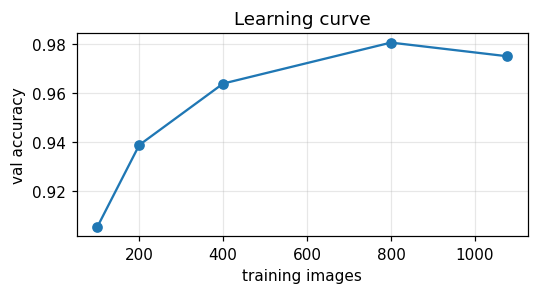

In [16]:
# Evidence for "do we need more data?" -> learning curve of the optimized setup
sizes = [100, 200, 400, 800, len(X_tr)]
curve = []
for n in sizes:
    pick = np.random.RandomState(0).choice(len(X_tr), n, replace=False)
    m = NumpyCNN(best_nf, lr=best_lr, seed=0).fit(X_tr[pick], y_tr[pick], epochs=40, augment=best_aug)
    curve.append((m.predict(X_va) == y_va).mean())
    print(f"train size {n:4d} -> val acc {curve[-1]:.3f}")

plt.figure(figsize=(5, 2.8)); plt.plot(sizes, curve, "o-"); plt.xlabel("training images"); plt.ylabel("val accuracy")
plt.title("Learning curve"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

plan = ["1. Move to larger, more varied data (MNIST / EMNIST / real scanned forms)",
        "2. Use a deeper CNN + pretrained backbone (ResNet/EfficientNet) in PyTorch",
        "3. Train with shift/scale augmentation if real scans are not centred",
        "4. Send low-confidence predictions to human review",
        "5. Monitor accuracy in production and retrain on new mistakes"]
print(); print("\n".join(plan))

**What this example tells us (according to the topic)**

- Learning curve (val acc): 100 images 0.906, 200 0.939, 400 0.964, 800 0.981, 1,077 0.975.
- It rises quickly then flattens near 800 images, so more of the same data adds little here.
- The bigger risks are real-world variation and robustness (topic 15). Priorities: more varied data, shift-robust training, pretrained/deeper models, human review for low confidence, monitoring.

**AI/ML Example**

Active learning: label the images the model is least sure about first.

**Business Example**

Roll out in phases: model reads, humans check low-confidence digits, then reduce checking as trust grows.

**AI/ML Engineer Use Case**

Turn each improvement into a ticket with an expected metric gain, cost and owner.

# 21.17 Explain What Each Hyperparameter Controls

**Concept**

Hyperparameters are settings we choose (not learned by the model) that control how the network is built and trained.

**Why it is required / what problem it solves**

Knowing what each one controls lets you diagnose underfitting and overfitting instead of guessing.

In [17]:
hp = pd.DataFrame([
    ("learning_rate", best_lr, "Step size of each weight update", "Too high: unstable loss. Too low: slow learning"),
    ("n_filters", best_nf, "How many patterns (edges/strokes) the conv layer can detect", "Too few: underfit. Too many: overfit, slower"),
    ("kernel size", "3x3", "Size of the area each filter looks at", "Small: fine detail. Large: more context, more params"),
    ("pool size", "2x2", "How much the feature map is shrunk", "Larger: more shift tolerance, loses detail"),
    ("epochs", 60, "Passes over the full training set", "Too few: underfit. Too many: overfit"),
    ("batch_size", 64, "Images used per weight update", "Small: noisy but regularizing. Large: smooth but slow"),
    ("l2 (weight decay)", 1e-4, "Penalty on large weights", "Too high: underfit. Too low: overfit"),
    ("augmentation", best_aug_name, "How much artificial variety is added", "Too strong: unrealistic images hurt accuracy"),
    ("optimizer", "Adam", "Rule used to update weights", "Adam adapts step sizes; SGD needs more tuning"),
], columns=["Hyperparameter", "Value used", "What it controls", "If wrong"])
pd.set_option("display.max_colwidth", 60, "display.width", 200)
print(hp.to_string(index=False))

   Hyperparameter Value used                                            What it controls                                              If wrong
    learning_rate       0.03                             Step size of each weight update       Too high: unstable loss. Too low: slow learning
        n_filters          8 How many patterns (edges/strokes) the conv layer can detect          Too few: underfit. Too many: overfit, slower
      kernel size        3x3                       Size of the area each filter looks at  Small: fine detail. Large: more context, more params
        pool size        2x2                          How much the feature map is shrunk            Larger: more shift tolerance, loses detail
           epochs         60                           Passes over the full training set                  Too few: underfit. Too many: overfit
       batch_size         64                               Images used per weight update Small: noisy but regularizing. Large: smooth but slow

**What this example tells us (according to the topic)**

- Values used: learning rate 0.03, 8 filters, 3x3 kernel, 2x2 pool, 60 epochs, batch 64, L2 1e-4, noise 0.05 augmentation, Adam.
- Underfitting (train and validation both low): more capacity or epochs, higher learning rate. Overfitting (train high, validation low): augmentation, L2, fewer epochs, more data.
- Seen in our runs: lr 0.001 underfit at 25 epochs; rotation augmentation hurt.

**AI/ML Example**

Dropout rate, weight decay and learning-rate warm-up in large vision models.

**Business Example**

Bigger models and longer training cost more compute and add latency, so hyperparameters affect budget.

**AI/ML Engineer Use Case**

Keep all hyperparameters in one config file, change one at a time, and log every run.